# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Evina Fitriyani | 5054251013 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **TensorFlow / Keras** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

### Deployment Model

Model CNN + BatchNorm + Dropout telah berhasil di-deploy menggunakan Modal dengan antarmuka Gradio.

Link Aplikasi:
https://efinafitriyani9898--fashion-mnist-classifier-ui.us-east.modal.run

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed dengan tf.keras.utils.set_random_seed(42).
# Cek apakah GPU tersedia dengan tf.config.list_physical_devices("GPU").

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

tf.keras.utils.set_random_seed(42)
print(tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

2.21.0
GPU: []


In [5]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

print('Ukuran data train:', train_df.shape)
print('Ukuran data test :', test_df.shape)

train_df.iloc[:5, :8]

Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7
0,2,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0
3,0,0,0,0,1,2,0,0
4,3,0,0,0,0,0,0,0


label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


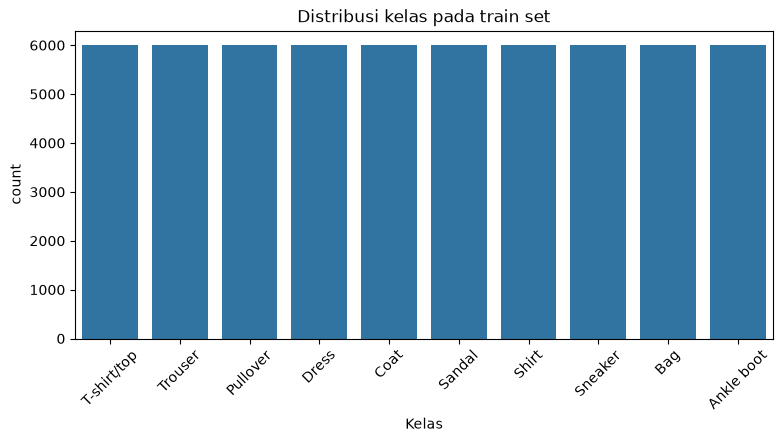

In [6]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(train_df['label'].value_counts().sort_index())

plt.figure(figsize=(9, 4))
sns.countplot(x='label', data=train_df)
plt.xticks(range(10), class_names, rotation=45)
plt.title('Distribusi kelas pada train set')
plt.xlabel('Kelas')
plt.show()

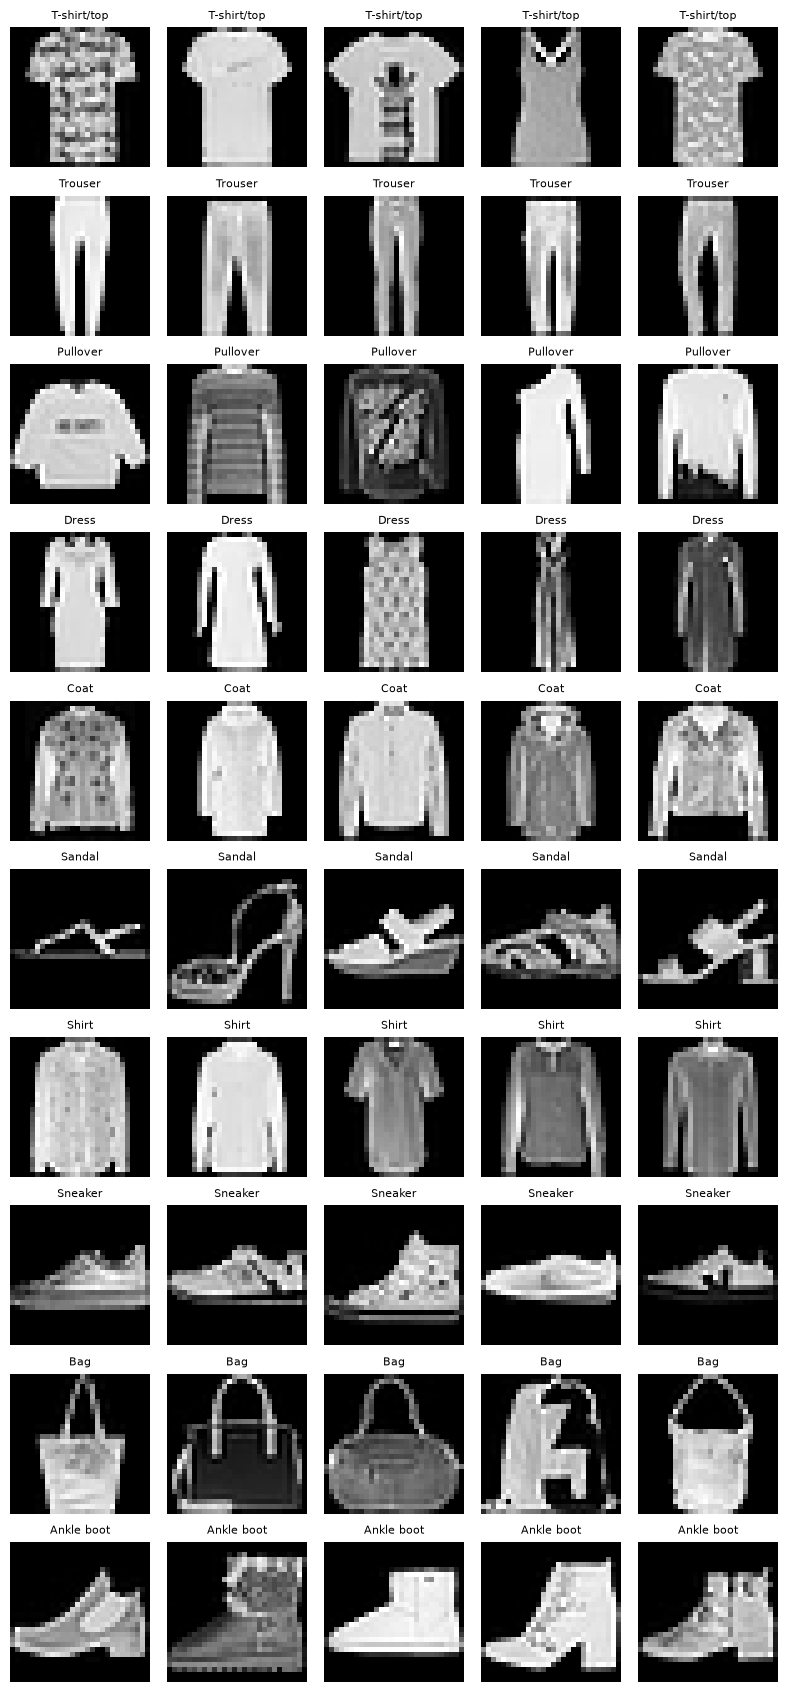

In [7]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

fig, ax = plt.subplots(10, 5, figsize=(8, 17))
for k in range(10):
    idx = train_df[train_df['label'] == k].index[:5]
    for j, i in enumerate(idx):
        ax[k, j].imshow(train_df.loc[i].drop('label').values.reshape(28, 28), cmap='gray')
        ax[k, j].set_title(class_names[k], fontsize=8)
        ax[k, j].axis('off')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Missing value train: 0 | test: 0
Rentang nilai piksel: 0 sampai 255
Distribusi label test:
{0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000}


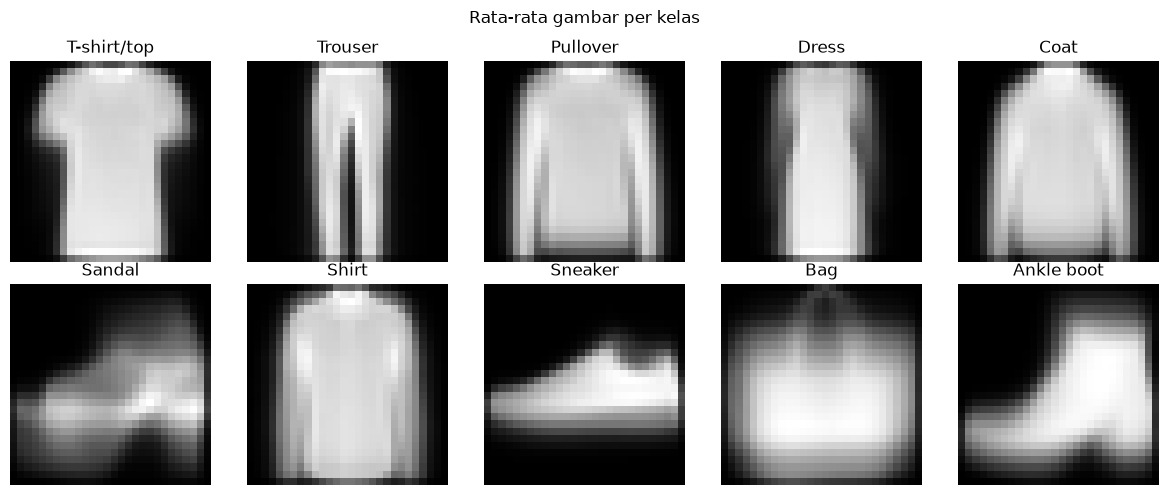

In [8]:
# cek missing value, rentang piksel, dan rata-rata gambar tiap kelas
print('Missing value train:', train_df.isnull().sum().sum(), '| test:', test_df.isnull().sum().sum())
pix = train_df.drop(columns='label').values
print('Rentang nilai piksel:', pix.min(), 'sampai', pix.max())
print('Distribusi label test:')
print(test_df['label'].value_counts().sort_index().to_dict())

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for k in range(10):
    mean_img = train_df[train_df['label'] == k].drop(columns='label').mean().values.reshape(28, 28)
    ax[k // 5, k % 5].imshow(mean_img, cmap='gray')
    ax[k // 5, k % 5].set_title(class_names[k])
    ax[k // 5, k % 5].axis('off')
plt.suptitle('Rata-rata gambar per kelas')
plt.tight_layout()
plt.show()

**Pengamatan EDA:**

- Datasetnya seimbang, tiap kelas punya 6.000 gambar di train set dan 1.000 gambar di test set. Tidak ada missing value, dan nilai piksel berkisar 0 sampai 255.
- Kelas yang kelihatan mirip adalah T-shirt/top, Shirt, Pullover, dan Coat, karena sama-sama pakaian atas berlengan dengan siluet yang hampir sama. Sandal, Sneaker, dan Ankle boot sama-sama alas kaki, tetapi bentuknya lebih mudah dibedakan.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di TensorFlow/Keras, urutan dimensi gambar adalah **(batch, tinggi, lebar, channel)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)` |
| CNN | `(N, 28, 28, 1)` |

In [9]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_train_full = train_df['label'].values
X_train_full = train_df.drop(columns='label').values
y_test = test_df['label'].values
X_test = test_df.drop(columns='label').values
print(X_train_full.shape, y_train_full.shape, X_test.shape, y_test.shape)

(60000, 784) (60000,) (10000, 784) (10000,)


In [10]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full / 255.0
X_test = X_test / 255.0
print('Rentang X_train_full:', X_train_full.min(), 'sampai', X_train_full.max())

Rentang X_train_full: 0.0 sampai 1.0


In [11]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1,
                                                  stratify=y_train_full, random_state=42)
print('Train:', X_train.shape)
print('Val  :', X_val.shape)
print('Test :', X_test.shape)

Train: (54000, 784)
Val  : (6000, 784)
Test : (10000, 784)


In [12]:
# Ubah bentuk data sesuai kebutuhan model (lihat tabel di atas), pastikan bertipe float32.
# Contoh untuk CNN: X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")

# bentuk untuk ANN (N, 784)
X_train_ann = X_train.astype('float32')
X_val_ann = X_val.astype('float32')
X_test_ann = X_test.astype('float32')

# bentuk untuk CNN (N, 28, 28, 1)
X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype('float32')
X_val_cnn = X_val.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test.reshape(-1, 28, 28, 1).astype('float32')

print('ANN:', X_train_ann.shape, X_val_ann.shape, X_test_ann.shape)
print('CNN:', X_train_cnn.shape, X_val_cnn.shape, X_test_cnn.shape)

ANN: (54000, 784) (6000, 784) (10000, 784)
CNN: (54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output dengan aktivasi Softmax** dan **`sparse_categorical_crossentropy`** sebagai loss function (label berupa angka 0-9).

Contoh arsitektur: `Input(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax)`

In [13]:
# Definisikan arsitektur ANN menggunakan keras.Sequential.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

tf.keras.utils.set_random_seed(42)

model_ann = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Compile model dengan optimizer, loss="sparse_categorical_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit() menggunakan validation_data, simpan hasilnya ke variabel history.

model_ann.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

history_ann = model_ann.fit(X_train_ann, y_train,
                            validation_data=(X_val_ann, y_val),
                            epochs=15, batch_size=128, verbose=0)

print('Epoch terakhir -> loss:', round(history_ann.history['loss'][-1], 4),
      '| val_loss:', round(history_ann.history['val_loss'][-1], 4))
print('Epoch terakhir -> acc:', round(history_ann.history['accuracy'][-1], 4),
      '| val_acc:', round(history_ann.history['val_accuracy'][-1], 4))

Epoch terakhir -> loss: 0.1827 | val_loss: 0.3678
Epoch terakhir -> acc: 0.9326 | val_acc: 0.8815


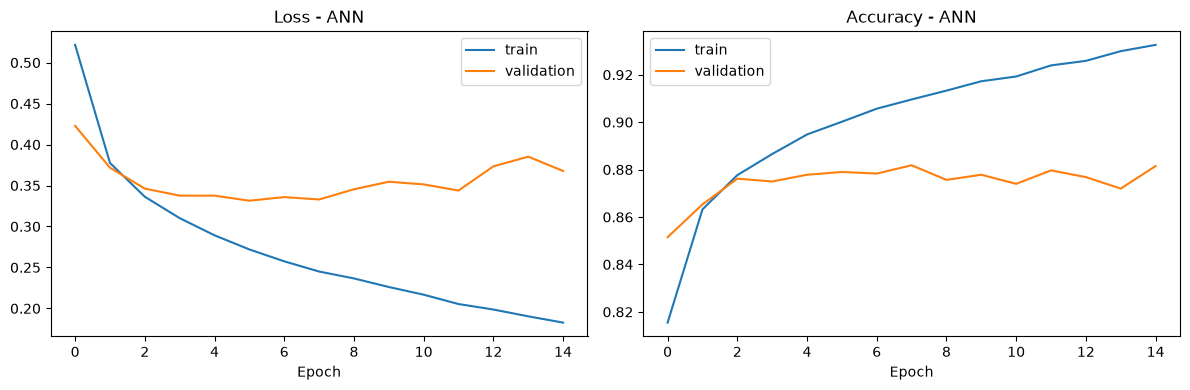

In [15]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_history(history, judul):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history['loss'], label='train')
    ax[0].plot(history.history['val_loss'], label='validation')
    ax[0].set_title('Loss - ' + judul)
    ax[0].set_xlabel('Epoch')
    ax[0].legend()
    ax[1].plot(history.history['accuracy'], label='train')
    ax[1].plot(history.history['val_accuracy'], label='validation')
    ax[1].set_title('Accuracy - ' + judul)
    ax[1].set_xlabel('Epoch')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_ann, 'ANN')

In [16]:
# Lakukan prediksi pada test set. model.predict() menghasilkan probabilitas 10 kelas,
# ambil kelas dengan probabilitas terbesar menggunakan argmax(axis=1). Simpan hasil prediksi label.

y_pred_ann = model_ann.predict(X_test_ann, verbose=0).argmax(axis=1)
print('Akurasi test ANN:', round(accuracy_score(y_test, y_pred_ann), 4))

Akurasi test ANN: 0.8832


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2D (ReLU) → MaxPooling, lalu dilanjutkan Flatten dan Dense.

Contoh arsitektur: `[Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2)] → [Conv2D(64, 3×3, ReLU) → MaxPooling2D(2×2)] → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`

In [17]:
# Definisikan arsitektur CNN sederhana menggunakan layers.Conv2D, layers.MaxPooling2D, layers.Flatten, dan layers.Dense.
# Gunakan keras.Input(shape=(28, 28, 1)) sebagai layer pertama.
# Tampilkan ringkasan model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1,
# lalu cocokkan dengan kolom "Output Shape" pada model.summary(). (padding="valid" berarti P = 0, padding="same" menjaga ukuran tetap)

tf.keras.utils.set_random_seed(42)

model_cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model_cnn.summary()

# hitung manual ukuran output: (W - K + 2P) / S + 1
def hitung(w, k, p, s):
    return (w - k + 2 * p) // s + 1

w = 28
print('Input          :', w, 'x', w, 'x 1')
w = hitung(w, 3, 0, 1)
print('Conv2D 3x3 (32):', w, 'x', w, 'x 32')
w = hitung(w, 2, 0, 2)
print('MaxPooling 2x2 :', w, 'x', w, 'x 32')
w = hitung(w, 3, 0, 1)
print('Conv2D 3x3 (64):', w, 'x', w, 'x 64')
w = hitung(w, 2, 0, 2)
print('MaxPooling 2x2 :', w, 'x', w, 'x 64')
print('Flatten        :', w * w * 64)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Input          : 28 x 28 x 1
Conv2D 3x3 (32): 26 x 26 x 32
MaxPooling 2x2 : 13 x 13 x 32
Conv2D 3x3 (64): 11 x 11 x 64
MaxPooling 2x2 : 5 x 5 x 64
Flatten        : 1600


Epoch terakhir -> loss: 0.1078 | val_loss: 0.3094
Epoch terakhir -> acc: 0.9624 | val_acc: 0.9053


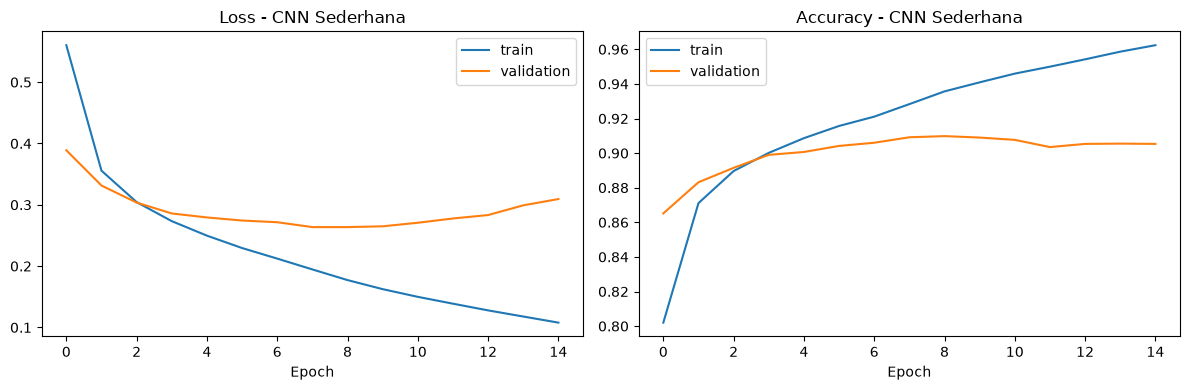

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

model_cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

history_cnn = model_cnn.fit(X_train_cnn, y_train,
                            validation_data=(X_val_cnn, y_val),
                            epochs=15, batch_size=128, verbose=0)

print('Epoch terakhir -> loss:', round(history_cnn.history['loss'][-1], 4),
      '| val_loss:', round(history_cnn.history['val_loss'][-1], 4))
print('Epoch terakhir -> acc:', round(history_cnn.history['accuracy'][-1], 4),
      '| val_acc:', round(history_cnn.history['val_accuracy'][-1], 4))

plot_history(history_cnn, 'CNN Sederhana')

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_cnn = model_cnn.predict(X_test_cnn, verbose=0).argmax(axis=1)
print('Akurasi test CNN sederhana:', round(accuracy_score(y_test, y_pred_cnn), 4))

Akurasi test CNN sederhana: 0.9101


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [20]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: Conv2D (tanpa activation) -> layers.BatchNormalization() -> layers.Activation("relu") -> MaxPooling2D.
# Tambahkan layers.Dropout(rate) sebelum layer output.
# Tampilkan ringkasan model beserta jumlah parameternya.

tf.keras.utils.set_random_seed(42)

model_cnn_bn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])
model_cnn_bn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

Epoch terakhir -> loss: 0.1501 | val_loss: 0.2813
Epoch terakhir -> acc: 0.9434 | val_acc: 0.9053


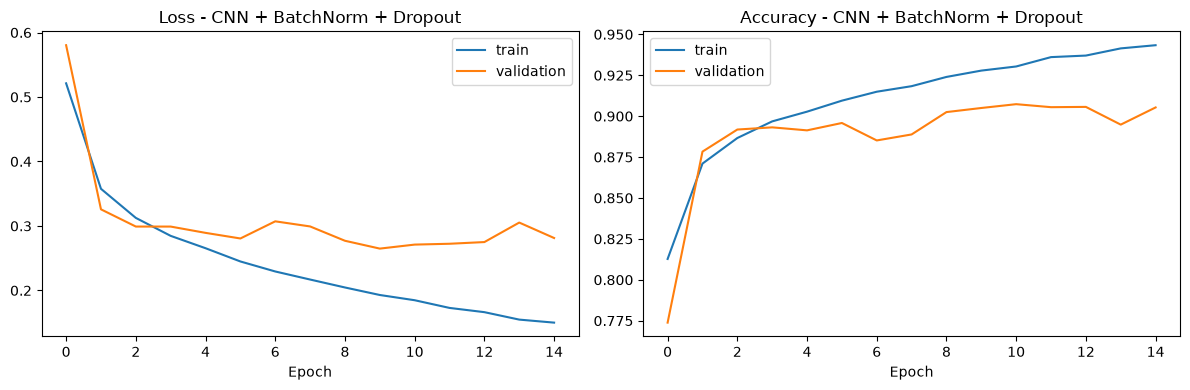

In [21]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

model_cnn_bn.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])

history_cnn_bn = model_cnn_bn.fit(X_train_cnn, y_train,
                                  validation_data=(X_val_cnn, y_val),
                                  epochs=15, batch_size=128, verbose=0)

print('Epoch terakhir -> loss:', round(history_cnn_bn.history['loss'][-1], 4),
      '| val_loss:', round(history_cnn_bn.history['val_loss'][-1], 4))
print('Epoch terakhir -> acc:', round(history_cnn_bn.history['accuracy'][-1], 4),
      '| val_acc:', round(history_cnn_bn.history['val_accuracy'][-1], 4))

plot_history(history_cnn_bn, 'CNN + BatchNorm + Dropout')

In [22]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_cnn_bn = model_cnn_bn.predict(X_test_cnn, verbose=0).argmax(axis=1)
print('Akurasi test CNN + BatchNorm + Dropout:', round(accuracy_score(y_test, y_pred_cnn_bn), 4))

Akurasi test CNN + BatchNorm + Dropout: 0.916


# 4. Evaluasi Model

In [23]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

hasil = {
    'ANN': (y_pred_ann, model_ann),
    'CNN Sederhana': (y_pred_cnn, model_cnn),
    'CNN + BatchNorm + Dropout': (y_pred_cnn_bn, model_cnn_bn)
}

baris = []
for nama, (yp, m) in hasil.items():
    baris.append([nama,
                  accuracy_score(y_test, yp),
                  precision_score(y_test, yp, average='macro'),
                  recall_score(y_test, yp, average='macro'),
                  f1_score(y_test, yp, average='macro'),
                  m.count_params()])

tabel_hasil = pd.DataFrame(baris, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Jumlah Parameter'])

best_name = tabel_hasil.loc[tabel_hasil['Accuracy'].idxmax(), 'Model']
best_model = hasil[best_name][1]
y_pred_best = hasil[best_name][0]
print('Model terbaik:', best_name)
tabel_hasil.round(4)

Model terbaik: CNN + BatchNorm + Dropout


,Model,Accuracy,Precision,Recall,F1-Score,Jumlah Parameter
0,ANN,0.8832,0.8880,0.8832,0.8844,235146
1,CNN Sederhana,0.9101,0.9122,0.9101,0.9105,225034
2,CNN + BatchNorm + Dropout,0.9160,0.9187,0.9160,0.9169,225418


In [24]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

print(classification_report(y_test, y_pred_best, target_names=class_names, digits=4))

              precision    recall  f1-score   support

 T-shirt/top     0.8842    0.8320    0.8573      1000
     Trouser     0.9949    0.9790    0.9869      1000
    Pullover     0.8693    0.8710    0.8701      1000
       Dress     0.9432    0.9140    0.9284      1000
        Coat     0.8869    0.8700    0.8783      1000
      Sandal     0.9809    0.9770    0.9790      1000
       Shirt     0.7205    0.8170    0.7657      1000
     Sneaker     0.9542    0.9580    0.9561      1000
         Bag     0.9919    0.9740    0.9828      1000
  Ankle boot     0.9613    0.9680    0.9646      1000

    accuracy                         0.9160     10000
   macro avg     0.9187    0.9160    0.9169     10000
weighted avg     0.9187    0.9160    0.9169     10000



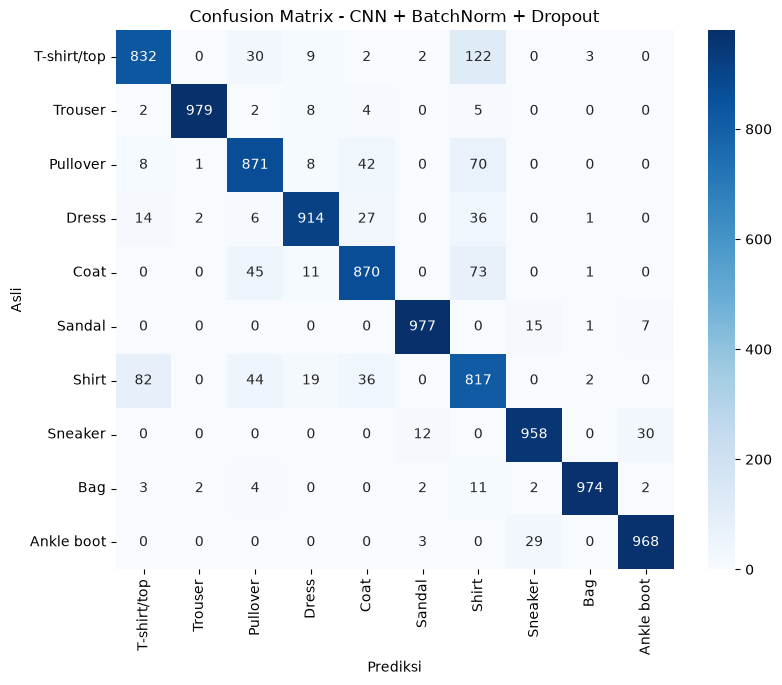

T-shirt/top -> diprediksi Shirt : 122
Shirt -> diprediksi T-shirt/top : 82
Coat -> diprediksi Shirt : 73
Pullover -> diprediksi Shirt : 70
Coat -> diprediksi Pullover : 45


In [25]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - ' + best_name)
plt.xlabel('Prediksi')
plt.ylabel('Asli')
plt.show()

# pasangan kelas yang paling sering tertukar
pasangan = []
for i in range(10):
    for j in range(10):
        if i != j:
            pasangan.append((cm[i, j], class_names[i], class_names[j]))
pasangan.sort(reverse=True)
for jumlah, asli, prediksi in pasangan[:5]:
    print(asli, '-> diprediksi', prediksi, ':', jumlah)

Jumlah salah prediksi: 840 dari 10000


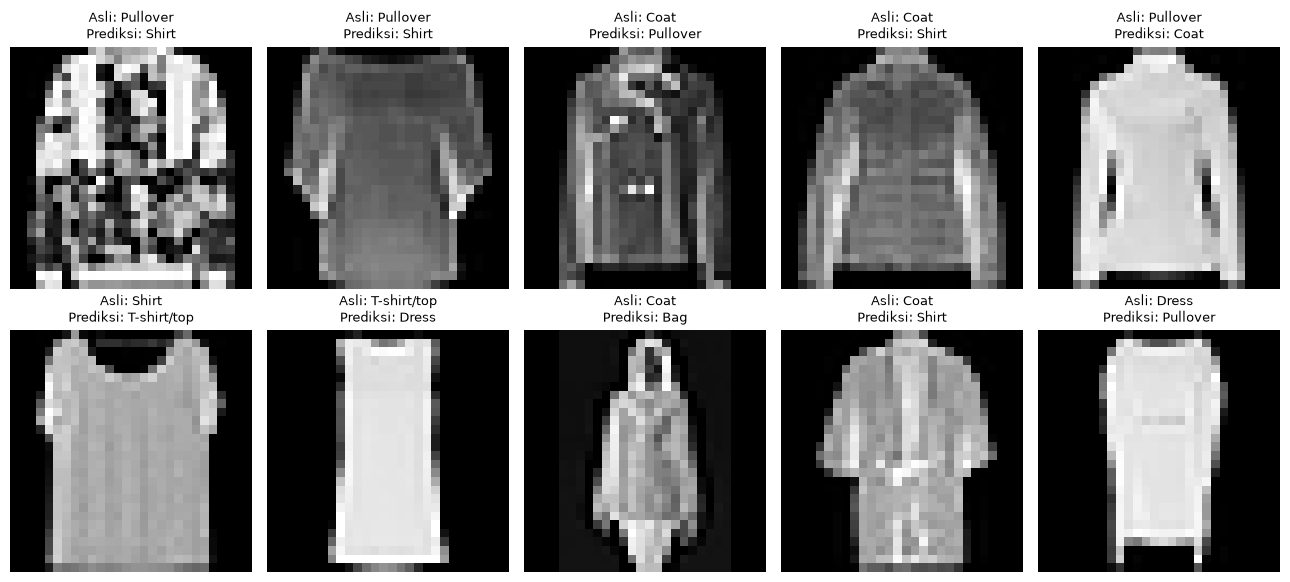

In [26]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

salah = np.where(y_pred_best != y_test)[0]
print('Jumlah salah prediksi:', len(salah), 'dari', len(y_test))

fig, ax = plt.subplots(2, 5, figsize=(13, 6))
for a, idx in zip(ax.ravel(), salah[:10]):
    a.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    a.set_title('Asli: ' + class_names[y_test[idx]] + '\nPrediksi: ' + class_names[y_pred_best[idx]], fontsize=9)
    a.axis('off')
plt.tight_layout()
plt.show()

Ukuran feature map: (1, 26, 26, 32)


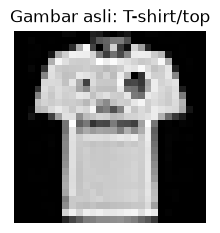

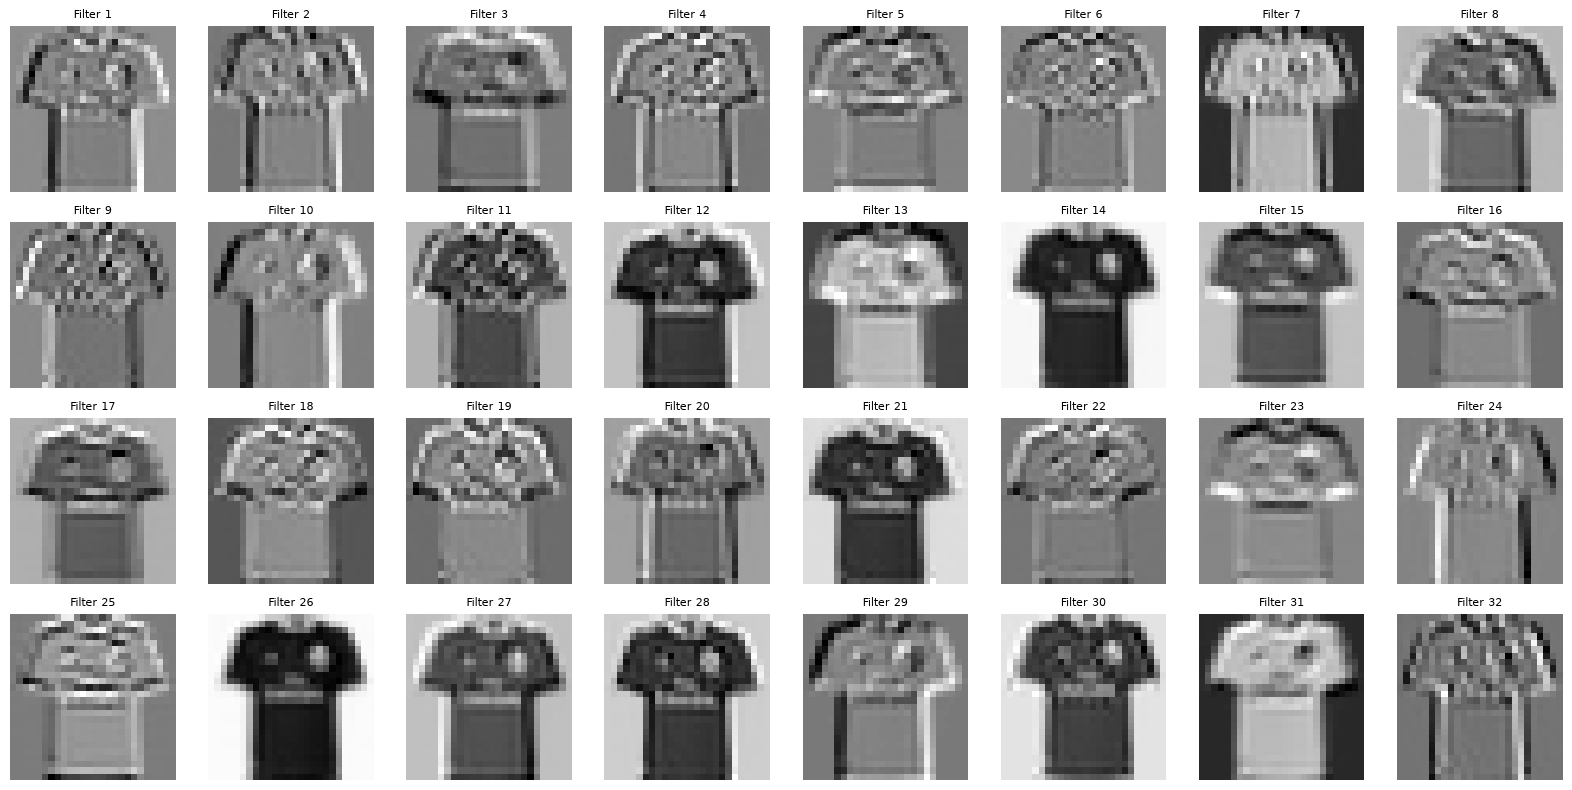

In [27]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Buat model baru yang output-nya adalah output layer konvolusi pertama:
#   feature_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
# lalu tampilkan setiap channel hasil feature_model.predict() sebagai gambar.
# Apa saja pola yang ditangkap oleh masing-masing filter?

img = X_test_cnn[0:1]
feature_model = keras.Model(inputs=best_model.inputs, outputs=best_model.layers[0].output)
fmap = feature_model.predict(img, verbose=0)
print('Ukuran feature map:', fmap.shape)

plt.figure(figsize=(2.5, 2.5))
plt.imshow(img[0, :, :, 0], cmap='gray')
plt.title('Gambar asli: ' + class_names[y_test[0]])
plt.axis('off')
plt.show()

n_filter = fmap.shape[-1]
fig, ax = plt.subplots(4, 8, figsize=(16, 8))
for k, a in enumerate(ax.ravel()):
    if k < n_filter:
        a.imshow(fmap[0, :, :, k], cmap='gray')
        a.set_title('Filter ' + str(k + 1), fontsize=8)
    a.axis('off')
plt.tight_layout()
plt.show()

In [28]:
# Simpan model terbaik dengan model.save("model.keras").
# Model ini akan digunakan kembali pada tugas Deployment.

best_model.save('model.keras')
print('Model tersimpan:', best_name)
print('Ukuran file model.keras:', round(os.path.getsize('model.keras') / 1024, 1), 'KB')

Model tersimpan: CNN + BatchNorm + Dropout
Ukuran file model.keras: 2695.3 KB


# 5. Analisis

#### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Jawaban:**

Perbandingan performa. CNN memberikan hasil lebih baik dibandingkan ANN. Accuracy ANN sebesar 0.8776, CNN sederhana 0.9052, dan CNN + BatchNorm + Dropout 0.9105. Penambahan BatchNorm dan Dropout juga meningkatkan hasil, meskipun selisihnya hanya sekitar 0.5%.

Jumlah parameter dan cara kerja model. Menariknya, CNN justru memiliki parameter sedikit lebih sedikit dibandingkan ANN. ANN memiliki 235.146 parameter, sedangkan CNN sekitar 225 ribu. Hal ini karena ANN mengubah gambar menjadi 784 angka, sedangkan CNN menggunakan filter untuk mengenali pola pada gambar, seperti tepi dan lengkungan. CNN juga bisa mengenali pola tersebut di berbagai posisi gambar sehingga lebih cocok untuk klasifikasi gambar.

Learning curve. Pada ANN dan CNN sederhana terlihat adanya overfitting karena performa training terus meningkat, sementara validation mulai melambat dan loss-nya meningkat. Setelah ditambahkan BatchNorm dan Dropout, jarak antara training dan validation menjadi lebih kecil. Artinya, kedua teknik tersebut membantu mengurangi overfitting, meskipun belum sepenuhnya menghilangkannya.

Kelas yang sulit dibedakan. Pada model terbaik, kelas Shirt memiliki F1 paling rendah, yaitu 0.7499. Beberapa kelas yang sering tertukar adalah Shirt dengan T-shirt/top, Shirt dengan Coat, serta Pullover dengan Coat. Menurut hasil eksperimen, hal ini kemungkinan karena bentuk pakaian tersebut cukup mirip, terutama jika dilihat dari gambar berukuran 28 × 28 piksel. Sebaliknya, kelas seperti Trouser, Sandal, dan Bag lebih mudah dikenali karena bentuknya lebih khas.

Feature map konvolusi pertama. Dari hasil visualisasi gambar ankle boot, terlihat beberapa filter mampu menangkap bagian tepi sepatu, seperti garis horizontal pada sol dan garis diagonal pada bagian atas. Ada juga filter yang menangkap bentuk keseluruhan sepatu. Artinya, layer konvolusi pertama masih mengenali pola dasar seperti tepi dan kontras warna, belum mengenali objek secara utuh.


# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan:**

CNN + BatchNorm + Dropout mendapatkan hasil terbaik dengan accuracy 0.9105 dan F1 macro 0.9097, disusul CNN sederhana dan ANN. Peningkatan paling besar terjadi saat menggunakan CNN dibandingkan ANN, yaitu sekitar 2,8%. Penambahan BatchNorm dan Dropout memang hanya meningkatkan accuracy sekitar 0,5%, tetapi membantu mengurangi overfitting. Model terbaik ini juga sudah disimpan sebagai model.keras untuk tugas Deployment.

Model masih cukup kesulitan membedakan pakaian yang bentuknya mirip, terutama Shirt, T-shirt/top, Pullover, dan Coat. Sementara itu, kelas seperti Trouser, Sandal, dan Bag lebih mudah dikenali.

**Saran:**

- Menggunakan EarlyStopping atau ModelCheckpoint agar model bisa berhenti atau menyimpan hasil training pada epoch terbaik.
- Mencoba data augmentation, seperti flip horizontal dan sedikit pergeseran gambar, untuk membantu mengurangi overfitting.
- Mencoba arsitektur CNN yang lebih dalam serta mengatur ulang nilai Dropout dan learning rate.
- Mengulang eksperimen dengan beberapa seed untuk memastikan hasilnya konsisten.
- Memperhatikan kelas Shirt karena masih memiliki nilai F1 paling rendah. Bisa dicoba penambahan data atau perbaikan model agar lebih mudah membedakan detail pakaian.
